In [1]:
!pip install transformers
!pip install --upgrade huggingface_hub
!pip install datasets jiwer evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 468.0/468.0 kB 8.3 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface-hub 0.28.1
    Uninstalling huggingface-hub-0.28.1:
      Successfully uninstalled huggingface-hub-0.28.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 40.3 MB/s eta 0:00:0000:0100:01
  Attempting uninstall: click
    Found existing installation: click 8.1.7
    Uninstalling click-8.1.7:
      Successfully uninstalled click-8.1.7


In [2]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
from transformers import TrOCRProcessor
from transformers import VisionEncoderDecoderModel
import torch
from torch.utils.data import Dataset
from PIL import Image

from huggingface_hub import login
access_token = user_secrets.get_secret("HF_Token")
login=login(token=access_token)

In [4]:
import pandas as pd

def import_dataset(path):
  df = pd.read_csv(path, sep='\t', usecols=[0,1], names=['file_name', 'text'])
  #df = pd.read_csv(path, sep='\t', usecols=[0,1])
  #df.rename(columns={'file': 'file_name', 'labels': 'text'}, inplace=True)
  return(df)

In [21]:
train_df = import_dataset('/kaggle/input/synthetic-word-small/train.tsv')
train_df = train_df.truncate(after=20000)
train_df.head()

,file_name,text
0,0_0.jpg,අභිමන්
1,0_1.jpg,දැහැණ
2,1_0.jpg,ඇන්තනී
3,2_0.jpg,නවීනභාවය
4,3_0.jpg,තොරතුරැ


In [22]:
test_df = import_dataset("/kaggle/input/synthetic-word-small/test.tsv")
test_df = test_df.truncate(after=4000)
test_df.head()

,file_name,text
0,0_0.jpg,ද්‍රවශීළ
1,2_0.jpg,බිස්කටි
2,1_0.jpg,පැල්මඩුල්ලටත්
3,3_0.jpg,ගුණාගුණ
4,0_1.jpg,ආදාරකය


In [7]:
import torch
from torch.utils.data import Dataset
from PIL import Image

class IAMDataset(Dataset):
    def __init__(self, root_dir, df, processor, max_target_length=128):
        self.root_dir = root_dir
        self.df = df
        self.processor = processor
        self.max_target_length = max_target_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # get file name + text
        file_name = self.df['file_name'][idx]
        if ".jpg" not in file_name:
          file_name = (file_name.split(".")[0]) + ".jpg"
        text = self.df['text'][idx]

        if text != "":
            # prepare image (i.e. resize + normalize)
            image = Image.open(self.root_dir + file_name).convert("RGB")
            pixel_values = self.processor(image, return_tensors="pt").pixel_values
            # add labels (input_ids) by encoding the text
            labels = self.processor.tokenizer(text,
                                              padding="max_length",
                                              max_length=self.max_target_length).input_ids
            # important: make sure that PAD tokens are ignored by the loss function
            labels = [label if label != self.processor.tokenizer.pad_token_id else -100 for label in labels]
    
            encoding = {"pixel_values": pixel_values.squeeze(), "labels": torch.tensor(labels)}
            return encoding

In [23]:
from transformers import TrOCRProcessor

processor = TrOCRProcessor.from_pretrained("ds1219/Pandithaya-TrOCR-Sinhala-Printed")
train_dataset = IAMDataset(root_dir='/kaggle/input/synthetic-word-small/train/',
                           df=train_df,
                           processor=processor)
eval_dataset = IAMDataset(root_dir='/kaggle/input/synthetic-word-small/test/',
                           df=test_df,
                           processor=processor)

In [24]:
print("Number of training examples:", len(train_dataset))
print("Number of validation examples:", len(eval_dataset))

Number of training examples: 20001
Number of validation examples: 4001


Let's verify an example from the training dataset:

In [25]:
encoding = eval_dataset[0]
for k,v in encoding.items():
  print(k, v.shape)

pixel_values torch.Size([3, 384, 384])
labels torch.Size([128])


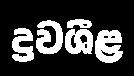

In [26]:
image = Image.open(eval_dataset.root_dir + train_df['file_name'][0]).convert("RGB")
image

In [27]:
labels = encoding['labels']
labels[labels == -100] = processor.tokenizer.pad_token_id
label_str = processor.decode(labels, skip_special_tokens=True)
print(label_str)

ද්රවශීළ


## Train a model

Here, we initialize the TrOCR model from its pretrained weights. Note that the weights of the language modeling head are already initialized from pre-training, as the model was already trained to generate text during its pre-training stage. Refer to the paper for details.

In [28]:
from transformers import VisionEncoderDecoderModel
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = VisionEncoderDecoderModel.from_pretrained("ds1219/Pandithaya-TrOCR-Sinhala-Printed-Words")
model.to(device)

Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": false,
  "transformers_version": "4.47.0"
}

Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "gelu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 768,
  "d_model": 1024,
  "decoder_attention_heads": 16,
  "decoder_ffn_dim": 4096,
  "decoder

VisionEncoderDecoderModel(
  (encoder): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTSdpaAttention(
            (attention): ViTSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=False)
              (key): Linear(in_features=768, out_features=768, bias=False)
              (value): Linear(in_features=768, out_features=768, bias=False)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linea

In [29]:
# set special tokens used for creating the decoder_input_ids from the labels
model.config.decoder_start_token_id = processor.tokenizer.cls_token_id
model.config.pad_token_id = processor.tokenizer.pad_token_id
# make sure vocab size is set correctly
model.config.vocab_size = model.config.decoder.vocab_size

# set beam search parameters
model.config.eos_token_id = processor.tokenizer.sep_token_id
model.config.max_length = 64
model.config.early_stopping = True
model.config.no_repeat_ngram_size = 3
model.config.length_penalty = 2.0
model.config.num_beams = 4

In [30]:
class TrainingConfig:
    BATCH_SIZE:    int = 8
    EPOCHS:         int = 1
    LEARNING_RATE: float = 0.00005

In [31]:
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments

training_args = Seq2SeqTrainingArguments(
    predict_with_generate=True,
    eval_strategy='steps',
    per_device_train_batch_size=TrainingConfig.BATCH_SIZE,
    per_device_eval_batch_size=TrainingConfig.BATCH_SIZE,
    fp16=True,
    output_dir="./model_training/",
    logging_steps=2,
    save_steps=1000,
    eval_steps=1000,
    report_to='tensorboard',
    num_train_epochs=TrainingConfig.EPOCHS,
    push_to_hub=True,
    hub_model_id = "ds1219/Pandithaya-TrOCR-Sinhala-Printed-Words",
    hub_private_repo=True,
    resume_from_checkpoint=True,
    load_best_model_at_end=True,
    metric_for_best_model="cer",
    weight_decay=0.01,
)

In [17]:
import evaluate

cer_metric = evaluate.load('cer')

In [32]:
def compute_metrics(pred):
    labels_ids = pred.label_ids
    pred_ids = pred.predictions

    # Decode predictions and labels
    pred_str = processor.batch_decode(pred_ids, skip_special_tokens=True)
    labels_ids[labels_ids == -100] = processor.tokenizer.pad_token_id
    label_str = processor.batch_decode(labels_ids, skip_special_tokens=True)

    # Initialize lists for filtered predictions and labels
    filtered_preds = []
    filtered_labels = []

    # Iterate over decoded predictions and labels
    for p, l in zip(pred_str, label_str):
        if l.strip():  # Check if the reference (label) is not empty
            filtered_preds.append(p)
            filtered_labels.append(l)
        else:
            print(f"Empty reference encountered. Prediction: '{p}'")  # Log the empty reference and its corresponding prediction

    # Compute CER
    cer = cer_metric.compute(predictions=filtered_preds, references=filtered_labels)

    return {"cer": cer}

In [ ]:
from transformers import default_data_collator

# instantiate trainer
trainer = Seq2SeqTrainer(
    model=model,
    tokenizer=processor.image_processor,
    args=training_args,
    compute_metrics=compute_metrics,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    data_collator=default_data_collator
)

res = trainer.train()

<ipython-input-33-4eb9f39df62d>:4: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Seq2SeqTrainer.__init__`. Use `processing_class` instead.
  trainer = Seq2SeqTrainer(


Step,Training Loss,Validation Loss


## Inference

Note that after training, you can easily load the model using the .`from_pretrained(output_dir)` method.

For inference on new images, I refer to my inference notebook, that can also be found in my [Transformers Tutorials repository](https://github.com/NielsRogge/Transformers-Tutorials) on Github.

In [24]:
device = torch.device('cuda:0' if torch.cuda.is_available else 'cpu')

In [25]:
processor = TrOCRProcessor.from_pretrained('ds1219/Pandithaya-TrOCR-Sinhala-Printed-Words-Dino-Roberta')
model = VisionEncoderDecoderModel.from_pretrained('ds1219/Pandithaya-TrOCR-Sinhala-Printed-Words-Dino-Roberta')
model.to(device)

/opt/conda/lib/python3.10/site-packages/transformers/tokenization_utils_base.py:1617: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be deprecated in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


config.json:   0%|          | 0.00/5.27k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/414M [00:00<?, ?B/s]

VisionEncoderDecoderModel(
  (encoder): Dinov2Model(
    (embeddings): Dinov2Embeddings(
      (patch_embeddings): Dinov2PatchEmbeddings(
        (projection): Conv2d(3, 384, kernel_size=(14, 14), stride=(14, 14))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): Dinov2Encoder(
      (layer): ModuleList(
        (0-11): 12 x Dinov2Layer(
          (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
          (attention): Dinov2Attention(
            (attention): Dinov2SelfAttention(
              (query): Linear(in_features=384, out_features=384, bias=True)
              (key): Linear(in_features=384, out_features=384, bias=True)
              (value): Linear(in_features=384, out_features=384, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): Dinov2SelfOutput(
              (dense): Linear(in_features=384, out_features=384, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
         

In [26]:
def read_and_show(image_path):
    """
    :param image_path: String, path to the input image.

    Returns:
        image: PIL Image.
    """
    image = Image.open(image_path).convert('RGB')
    
    return image

In [27]:
def ocr(image):
    """
    :param image: PIL Image.
    :param processor: Huggingface OCR processor.
    :param model: Huggingface OCR model.

    Returns:
        generated_text: the OCR'd text string.
    """
    # We can directly perform OCR on cropped images.
    pixel_values = processor(image, return_tensors='pt').pixel_values.to(device)
    generated_ids = model.generate(pixel_values)
    generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    return generated_text

In [32]:
image = read_and_show('/kaggle/input/synthetic-word-small/train/0_0.jpg')
text = ocr(image)
print(text)

සිතුවෙන්න


In [29]:
trained_model.push_to_hub("ds1219/Pandithaya-TrOCR-Sinhala-Printed")

NameError: name 'trained_model' is not defined

# Evaluate

In [26]:
test_df = import_dataset('/kaggle/input/real-small/Archive/test.tsv')
test_df.head()

,file_name,text
0,01-4.jpg,රැකවලා විහින් අමාරුවේ
1,01-6.jpg,ටෝනි ඇබට් අභියෝගය භාරගනී
2,02-2.jpg,රටවල් කිහිපයක් උතුරු කොරියාවට එරෙහිව නව සම්බාධ...
3,02-6.jpg,රට ගොඩනැගීමට ජනාධිපතිතුමාට යම් කාලයක් ලබා දෙන්න
4,13-4.jpg,වරායේ නැගෙනහිර පර්යන්තයේ දෙවන අදියරේ ඉදිකිරීම්...


In [43]:
from transformers import VisionEncoderDecoderModel
from transformers import TrOCRProcessor, AutoTokenizer, ViTImageProcessor
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

#model = VisionEncoderDecoderModel.from_pretrained("ds1219/Pandithaya-TrOCR-Sinhala-Handwritten")
#processor = TrOCRProcessor.from_pretrained("ds1219/Pandithaya-TrOCR-Sinhala-Printed")

#processor = TrOCRProcessor.from_pretrained('Ransaka/TrOCR-Sinhala')
#model = VisionEncoderDecoderModel.from_pretrained('Ransaka/TrOCR-Sinhala')

#model = VisionEncoderDecoderModel.from_pretrained("kavg/TrOCR-SIN-DeiT-Handwritten")
#tokenizer = AutoTokenizer.from_pretrained('NLPC-UOM/SinBERT-large')
#feature_extractor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")
#processor = TrOCRProcessor(image_processor=feature_extractor, tokenizer=tokenizer)

model = VisionEncoderDecoderModel.from_pretrained("kavg/TrOCR-SIN-Handwritten")
tokenizer = AutoTokenizer.from_pretrained('NLPC-UOM/SinBERT-large')
feature_extractor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")
processor = TrOCRProcessor(image_processor=feature_extractor, tokenizer=tokenizer)
model.to(device)

config.json:   0%|          | 0.00/77.8k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/963M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/251 [00:00<?, ?B/s]

VisionEncoderDecoderModel(
  (encoder): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_featur

In [44]:
import torch
from torch.utils.data import Dataset
from PIL import Image

class IAMDataset(Dataset):
    def __init__(self, root_dir, df, processor, max_target_length=128):
        self.root_dir = root_dir
        self.df = df
        self.processor = processor
        self.max_target_length = max_target_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # get file name + text 
        file_name = self.df['file_name'][idx]
        text = self.df['text'][idx]
        # some file names end with jp instead of jpg, the two lines below fix this
        if ".jpg" not in file_name:
          file_name = (file_name.split(".")[0]) + ".jpg"
        # prepare image (i.e. resize + normalize)
        image = Image.open(self.root_dir + file_name).convert("RGB")
        pixel_values = self.processor(image, return_tensors="pt").pixel_values
        # add labels (input_ids) by encoding the text
        labels = self.processor.tokenizer(text, 
                                          padding="max_length", 
                                          max_length=self.max_target_length).input_ids
        # important: make sure that PAD tokens are ignored by the loss function
        labels = [label if label != self.processor.tokenizer.pad_token_id else -100 for label in labels]

        encoding = {"pixel_values": pixel_values.squeeze(), "labels": torch.tensor(labels)}
        return encoding
        
test_dataset = IAMDataset(root_dir='/kaggle/input/real-small/Archive/test/',
                           df=test_df,
                           processor=processor)

from torch.utils.data import DataLoader

test_dataloader = DataLoader(test_dataset, batch_size=8)
batch = next(iter(test_dataloader))
for k,v in batch.items():
  print(k, v.shape)

labels = batch["labels"]
labels[labels == -100] = processor.tokenizer.pad_token_id
label_str = processor.batch_decode(labels, skip_special_tokens=True)
label_str

pixel_values torch.Size([8, 3, 224, 224])
labels torch.Size([8, 128])


['රැකවලා විහින් අමාරුවේ',
 'ටෝනි ඇබට් අභියෝගය භාරගනී',
 'රටවල් කිහිපයක් උතුරු කොරියාවට එරෙහිව නව සම්බාධක පනවයි',
 'රට ගොඩනැගීමට ජනාධිපතිතුමාට යම් කාලයක් ලබා දෙන්න',
 'වරායේ නැගෙනහිර පර්යන්තයේ දෙවන අදියරේ ඉදිකිරීම් අරඹයි',
 'වතුකම්කරුවන් ඉන්ධන පිරවුම්හල වටලයි',
 'මලියදේවේ ළඟ ගුරු උද්ඝෝෂණයක්',
 'පළාත් කිහිපයකට වැසිබර කාලගුණයක්']

In [45]:
import evaluate

cer = evaluate.load('cer')

In [46]:
from tqdm.notebook import tqdm

print("Running evaluation...")

for batch in tqdm(test_dataloader):
    # predict using generate
    pixel_values = batch["pixel_values"].to(device)
    outputs = model.generate(pixel_values)

    # decode
    pred_str = processor.batch_decode(outputs, skip_special_tokens=True)
    labels = batch["labels"]
    labels[labels == -100] = processor.tokenizer.pad_token_id
    label_str = processor.batch_decode(labels, skip_special_tokens=True)

    # add batch to metric
    cer.add_batch(predictions=pred_str, references=label_str)

final_score = cer.compute()

Running evaluation...


  0%|          | 0/3 [00:00<?, ?it/s]

In [47]:
print("Character error rate on test set:", final_score)

Character error rate on test set: 0.913312693498452
